In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

results = pd.read_csv("results.csv")    ## load the table saved by main.ipynb
results.head()

,person,robot,theta,leak,leak2,user_cost,user_cost_sd,C,C_sd,non_user_cost,non_user_cost_sd,final_theta_mean,final_theta_mean_sd,non_user_regret_mean,non_user_regret_sd,user_regret_mean,user_regret_sd
0,YESMAN(theta=0),Baseline,0.0,1.0,1.0,0.993000,0.019505,1.000000,0.000000,1.500000,0.021807,NaN,NaN,0.000000,0.000000,0.000000,0.000000
1,YESMAN(theta=0),naive,0.0,1.0,1.0,7.637667,0.170589,0.273333,0.019861,0.423667,0.038505,NaN,NaN,-1.076333,0.052455,6.644667,0.168425
2,YESMAN(theta=0),behavior,0.0,1.0,1.0,2.524333,0.738224,0.821667,0.085460,1.238667,0.115535,NaN,NaN,-0.261333,0.131265,1.531333,0.720069
3,YESMAN(theta=0),preference,0.0,1.0,1.0,2.874000,0.835649,0.797333,0.089167,1.199667,0.109866,1.226298e+00,6.301082e-01,-0.300333,0.125890,1.881000,0.822318
4,YESMAN(theta=0),preference_face,0.0,1.0,1.0,1.442667,0.026721,0.951000,0.001333,1.422667,0.028158,9.942287e-10,5.109199e-10,-0.077333,0.015041,0.449667,0.011518


In [2]:
def get_value(theta, leak, robot_name, column):
    ## all rows for this person-condition and robot (one per leak2 value)
    rows = results[(results['theta'] == theta) & (results['leak'] == leak) & (results['robot'] == robot_name)]

    ## prefer the leak2 = 0.6 row; if there isn't one (θ10 at λb = 1), use the row that exists
    preferred = rows[rows['leak2'] == 0.6]
    if len(preferred) > 0:
        rows = preferred

    return rows[column].iloc[0]    ## .iloc[0] = "the first row", as a plain number

In [3]:
print(get_value(10, 0.2, 'behavior', 'non_user_regret_mean'))         ## should be 4.89
print(get_value(10, 1.0, 'preference_face', 'final_theta_mean'))      ## should be 10.0 (the NOMAN row)

4.885000000000001
10.0


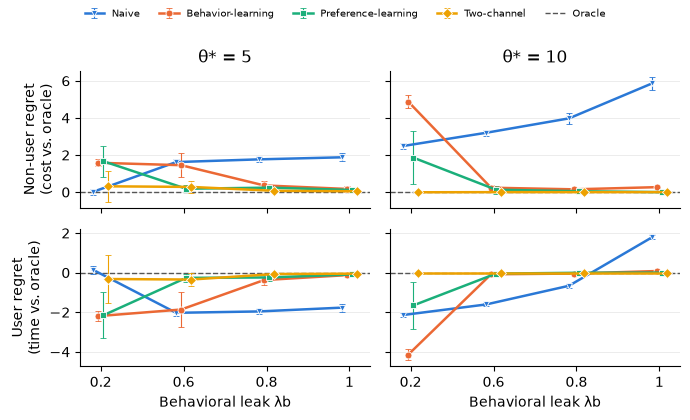

In [8]:
from matplotlib.lines import Line2D

robot_names = ['naive', 'behavior', 'preference', 'preference_face']
labels      = ['Naive', 'Behavior-learning', 'Preference-learning', 'Two-channel']
colors      = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
markers     = ['v', 'o', 's', 'D']

thetas = [5, 10]
leaks  = [0.2, 0.6, 0.8, 1.0]
measures = ['non_user_regret', 'user_regret']
x = np.arange(len(leaks))
offsets = [-0.09, -0.03, 0.03, 0.09]    ## nudge each robot sideways so error bars don't sit on top of each other

fig, axes = plt.subplots(2, 2, figsize=(7, 4.2), sharex=True, sharey='row')

for col, theta in enumerate(thetas):
    for row, measure in enumerate(measures):
        ax = axes[row, col]
        ax.axhline(0, color='#555', linewidth=1, linestyle='--', zorder=1)    ## dashed line = the oracle

        for i, robot_name in enumerate(robot_names):
            means, sds = [], []
            for leak in leaks:
                means.append(get_value(theta, leak, robot_name, measure + '_mean'))
                sds.append(get_value(theta, leak, robot_name, measure + '_sd'))

            ax.errorbar(x + offsets[i], means, yerr=sds, color=colors[i], marker=markers[i],
                        markersize=5, linewidth=1.8, elinewidth=0.8, capsize=2,
                        markeredgecolor='white', markeredgewidth=0.6, label=labels[i], zorder=3)

        ax.grid(axis='y', color='#e5e5e5', linewidth=0.5)
        ax.set_axisbelow(True)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    axes[0, col].set_title(f"θ* = {theta}")
    axes[1, col].set_xticks(x, ['0.2', '0.6', '0.8', '1'])
    axes[1, col].set_xlabel("Behavioral leak λb")

axes[0, 0].set_ylabel("Non-user regret\n(cost vs. oracle)")
axes[1, 0].set_ylabel("User regret\n(time vs. oracle)")

## legend: the four robots, plus a hand-made entry for the dashed oracle line
handles, legend_labels = axes[0, 0].get_legend_handles_labels()
handles.append(Line2D([0], [0], color='#555', linewidth=1, linestyle='--'))
legend_labels.append('Oracle')
fig.legend(handles, legend_labels, ncol=5, fontsize=7, loc='upper center', frameon=False)

plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.savefig("fig3_regret.png", dpi=300)
plt.show()

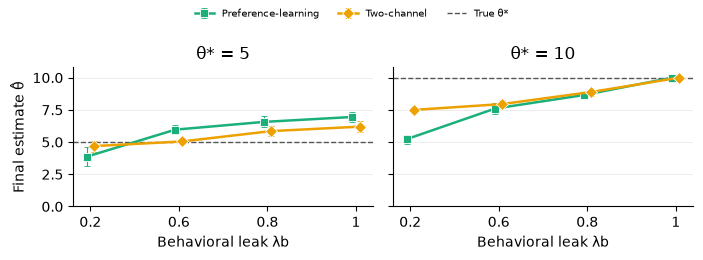

In [9]:
## ---------- Fig. 4: the robot's final estimate of theta, across behavioral leak ----------
robot_names = ['preference', 'preference_face']
labels      = ['Preference-learning', 'Two-channel']
colors      = ['#1baf7a', '#eda100']
markers     = ['s', 'D']

thetas = [5, 10]
leaks  = [0.2, 0.6, 0.8, 1.0]
x = np.arange(len(leaks))
offsets = [-0.04, 0.04]

fig, axes = plt.subplots(1, 2, figsize=(7, 2.6), sharey=True)

for col, theta in enumerate(thetas):
    ax = axes[col]
    ax.axhline(theta, color='#555', linewidth=1, linestyle='--', zorder=1)    ## dashed line = the true theta

    for i, robot_name in enumerate(robot_names):
        means, sds = [], []
        for leak in leaks:
            means.append(get_value(theta, leak, robot_name, 'final_theta_mean'))
            sds.append(get_value(theta, leak, robot_name, 'final_theta_mean_sd'))

        ax.errorbar(x + offsets[i], means, yerr=sds, color=colors[i], marker=markers[i],
                    markersize=6, linewidth=1.8, elinewidth=0.8, capsize=2,
                    markeredgecolor='white', markeredgewidth=0.6, label=labels[i], zorder=3)

    ax.set_title(f"θ* = {theta}")
    ax.set_xticks(x, ['0.2', '0.6', '0.8', '1'])
    ax.set_xlabel("Behavioral leak λb")
    ax.set_ylim(0, 10.8)
    ax.grid(axis='y', color='#e5e5e5', linewidth=0.5)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

axes[0].set_ylabel("Final estimate θ̂")

## legend: the two robots, plus a hand-made entry for the dashed true-theta line
handles, legend_labels = axes[0].get_legend_handles_labels()
handles.append(Line2D([0], [0], color='#555', linewidth=1, linestyle='--'))
legend_labels.append('True θ*')
fig.legend(handles, legend_labels, ncol=3, fontsize=7, loc='upper center', frameon=False)

plt.tight_layout(rect=(0, 0, 1, 0.9))
plt.savefig("fig4_theta_hat.png", dpi=300)
plt.show()

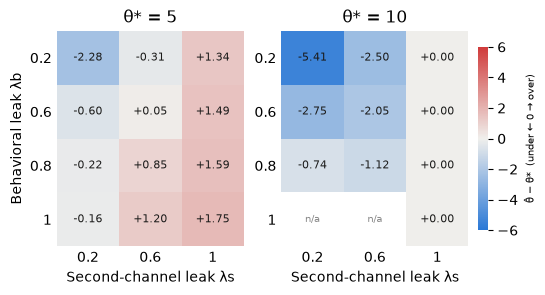

In [11]:
## ---------- Fig. 5: two-channel robot's error (theta-hat minus true theta), for every lambda_b x lambda_s ----------
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

## get_value() always prefers leak2 = 0.6; here we need every leak2, so this version takes leak2 directly
def get_value_exact(theta, leak, leak2, robot_name, column):
    rows = results[(results['theta'] == theta) & (results['leak'] == leak) &
                   (results['leak2'] == leak2) & (results['robot'] == robot_name)]
    if len(rows) == 0:
        return np.nan                      ## this condition wasn't run (theta 10 at lambda_b = 1 with lambda_s < 1)
    return rows[column].iloc[0]

thetas = [5, 10]
leaks  = [0.2, 0.6, 0.8, 1.0]              ## rows of the grid
leak2s = [0.2, 0.6, 1.0]                   ## columns of the grid

## blue = guessed too low, grey = right, red = guessed too high
cmap = LinearSegmentedColormap.from_list("diverging", ['#2a78d6', '#f0efec', '#d03b3b'])
norm = TwoSlopeNorm(vmin=-6, vcenter=0, vmax=6)    ## 0 always sits at the grey middle

fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.8))

for col, theta in enumerate(thetas):
    ax = axes[col]

    ## build the grid: one row per lambda_b, one column per lambda_s
    error = np.zeros((len(leaks), len(leak2s)))
    for r, leak in enumerate(leaks):
        for c, leak2 in enumerate(leak2s):
            error[r, c] = get_value_exact(theta, leak, leak2, 'preference_face', 'final_theta_mean') - theta

    image = ax.imshow(error, cmap=cmap, norm=norm, aspect='auto')

    ## write the number in each cell; mark cells that weren't run
    for r in range(len(leaks)):
        for c in range(len(leak2s)):
            if np.isnan(error[r, c]):
                ax.text(c, r, "n/a", ha='center', va='center', fontsize=7, color='#888')
            else:
                ax.text(c, r, f"{error[r, c]:+.2f}", ha='center', va='center', fontsize=8, color='#1a1a19')

    ax.set_xticks(range(len(leak2s)), ['0.2', '0.6', '1'])
    ax.set_yticks(range(len(leaks)), ['0.2', '0.6', '0.8', '1'])
    ax.set_xlabel("Second-channel leak λs")
    ax.set_title(f"θ* = {theta}")
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

axes[0].set_ylabel("Behavioral leak λb")
colorbar = fig.colorbar(image, ax=axes, shrink=0.85, pad=0.02)
colorbar.set_label("θ̂ − θ*  (under ← 0 → over)", fontsize=7)
colorbar.outline.set_visible(False)

plt.savefig("fig5_second_channel.png", dpi=300, bbox_inches='tight')
plt.show()